# 09 — Logistic regression

| | |
| --- | --- |
| **Prerequisites** | Notebooks 00–08: tensors, gradients and gradient descent, likelihood and binary cross-entropy (04), autograd, the training loop (06), the perceptron and linear separability (07–08) |
| **You will learn** | The sigmoid as a soft threshold; reading a linear model as log-odds; why binary cross-entropy, not squared error, is the loss for probabilities; the gradient $\frac1N X^\top(\hat{\mathbf p} - \mathbf y)$ and the Hessian $\frac1N X^\top S X$; why the loss is convex; training from scratch and with `nn.Linear`; computing the loss stably from logits; what goes wrong on separable data; a first look at calibration |
| **Estimated time** | About 3 hours, plus 1–2 hours for the exercises |
| **Compute** | CPU only, well under a minute. No GPU section: every model here has three parameters. |

## Setup

In [1]:
# Setup: make the course helpers importable and record the environment.
import sys
from pathlib import Path

try:
    import dlcourse
except ImportError:  # running without `uv sync`, e.g. on Colab after cloning the repo
    root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dlcourse").is_dir())
    sys.path.insert(0, str(root))
    import dlcourse

import matplotlib.pyplot as plt
import torch

from dlcourse import check, check_close, check_shape, passed, set_seed
from dlcourse.plotting import setup_style

setup_style()
device = dlcourse.describe_environment()
set_seed(0)

Python  3.12.13 (Darwin arm64)
PyTorch 2.14.1
CUDA available: False
MPS available:  True
Selected device: mps


In [2]:
import math

import torch.nn.functional as F
from torch import nn

from dlcourse.data import make_blobs, make_xor
from dlcourse.plotting import COLORS, plot_dataset, plot_decision_boundary

f64 = torch.float64

## The motivating problem

Two classes of points overlap: some class-0 points sit in class-1 territory and vice versa, so **no line separates them perfectly**. Notebook 08 showed what the perceptron does on such data: it never stops making mistakes, so it never stops updating. Let's watch it, using the perceptron rule of notebook 07 with labels $t \in \{-1, +1\}$: for each example in turn, if $t_i(\mathbf w \cdot \mathbf x_i + b) \le 0$, update $\mathbf w \leftarrow \mathbf w + t_i \mathbf x_i$ and $b \leftarrow b + t_i$.

In [3]:
X_blob, y_blob = make_blobs(n=200, std=1.0, seed=0)   # X: (400, 2) float32, y: (400,) int64 in {0, 1}
N = len(X_blob)


def perceptron_train(X, y, epochs, seed):
    """Perceptron rule (notebook 07). y in {0, 1}. Visits examples in a seeded random order each epoch.
    Returns w (D,), b (), and the number of mistakes in each epoch."""
    gen = torch.Generator().manual_seed(seed)
    t = 2 * y.float() - 1                       # (N,) labels in {-1, +1}
    w, b = torch.zeros(X.shape[1]), torch.zeros(())
    mistakes = []
    for _ in range(epochs):
        count = 0
        for i in torch.randperm(len(X), generator=gen).tolist():
            if t[i] * (X[i] @ w + b) <= 0:
                w, b = w + t[i] * X[i], b + t[i]
                count += 1
        mistakes.append(count)
    return w, b, mistakes


for epochs in [17, 18, 19, 20]:
    w_p, b_p, mistakes = perceptron_train(X_blob, y_blob, epochs, seed=0)
    acc = (((X_blob @ w_p + b_p) > 0).long() == y_blob).float().mean().item()
    print(f"after {epochs} epochs: w = {[round(v, 2) for v in w_p.tolist()]}, b = {b_p.item():5.1f}, "
          f"mistakes in last epoch = {mistakes[-1]:2d}, training accuracy = {acc:.3f}")

after 17 epochs: w = [3.3, 2.16], b =   1.0, mistakes in last epoch = 39, training accuracy = 0.928
after 18 epochs: w = [3.66, 1.97], b =  -1.0, mistakes in last epoch = 44, training accuracy = 0.933
after 19 epochs: w = [2.62, 1.1], b =   1.0, mistakes in last epoch = 40, training accuracy = 0.900
after 20 epochs: w = [2.82, 2.8], b =  -1.0, mistakes in last epoch = 48, training accuracy = 0.930


The perceptron keeps making mistakes every epoch, so its weights keep jumping, and the answer depends on exactly when we stop. Its output is also a hard yes/no: a point right on the boundary and a point far inside class 1 get the same answer, "1".

**Can we build a linear classifier that outputs a probability — how sure it is — and is trained by minimizing a smooth loss that has a single best answer?** That classifier is **logistic regression**. It is also exactly the last layer of almost every binary classifier in deep learning.

## 1. From step to sigmoid

The perceptron computes the **logit** $z = \mathbf w \cdot \mathbf x + b$ and outputs $\operatorname{step}(z)$: 1 if $z > 0$, else 0. The step function is useless for gradient descent: its derivative is 0 everywhere except at $z = 0$, where it does not exist. A small change of $\mathbf w$ almost never changes the output, so the gradient carries no information about which way to move.

Replace the step by the **sigmoid** (logistic function), already met in notebook 03:

$$\sigma(z) = \frac{1}{1 + e^{-z}}.$$

Its properties, each easy to check:

- $0 < \sigma(z) < 1$ for every real $z$, because $e^{-z} > 0$.
- $\sigma(0) = \frac{1}{1 + 1} = \frac12$.
- **Symmetry:** $\sigma(-z) = \dfrac{1}{1 + e^{z}} = \dfrac{e^{-z}}{e^{-z} + 1} = 1 - \sigma(z)$ (multiply top and bottom by $e^{-z}$).
- $\sigma(z) \to 1$ as $z \to \infty$ and $\to 0$ as $z \to -\infty$.
- $\sigma'(z) = \sigma(z)(1 - \sigma(z))$ (derived in notebook 03), which is positive, so $\sigma$ is strictly increasing, and is largest, $\frac14$, at $z = 0$.

In [4]:
z = torch.linspace(-30, 30, 6001, dtype=f64)   # (6001,) grid of logits
s = torch.sigmoid(z)
print("σ(0)                    =", torch.sigmoid(torch.tensor(0.0)).item())
print("max |σ(-z) - (1 - σ(z))| =", (torch.sigmoid(-z) - (1 - s)).abs().max().item())
print("range of σ on the grid   :", s.min().item(), "to", s.max().item())
ds = s * (1 - s)                                # σ'(z)
print(f"max σ'(z) = {ds.max().item():.6f} at z = {z[ds.argmax()].item()}")
print("σ strictly increasing on the grid:", bool((s[1:] > s[:-1]).all()))

σ(0)                    = 0.5
max |σ(-z) - (1 - σ(z))| = 1.5959455978986625e-16
range of σ on the grid   : 9.357622968839299e-14 to 0.9999999999999065
max σ'(z) = 0.250000 at z = -6.245004513516506e-16
σ strictly increasing on the grid: True


All five properties hold numerically. (On a `float64` grid out to $|z| = 30$, $\sigma$ never reaches exactly 0 or 1; Section 6 shows that in `float32` it does, and why that matters.)

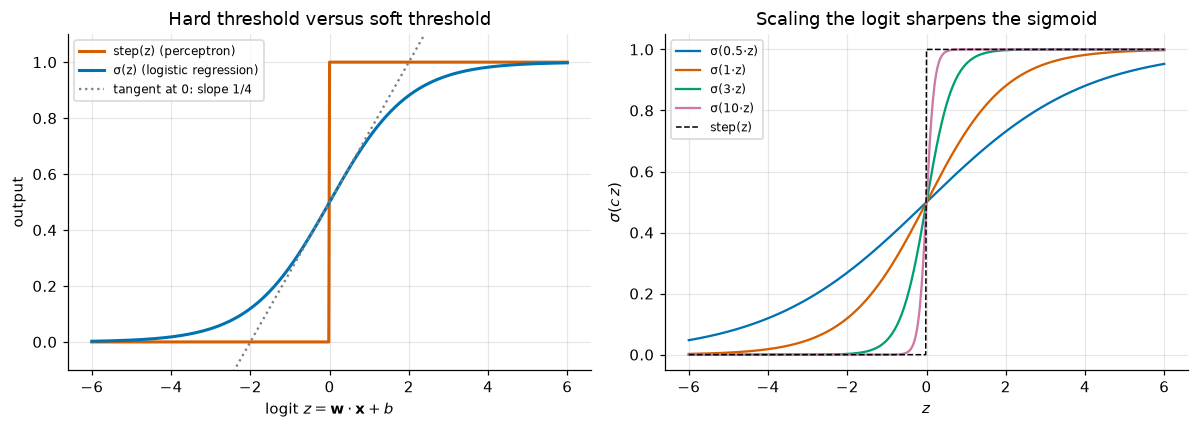

In [5]:
zz = torch.linspace(-6, 6, 601)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(zz, (zz > 0).float(), color=COLORS[1], lw=2, label="step(z) (perceptron)")
ax1.plot(zz, torch.sigmoid(zz), color=COLORS[0], lw=2, label="σ(z) (logistic regression)")
ax1.plot(zz, 0.5 + zz / 4, color="gray", ls=":", label="tangent at 0: slope 1/4")
ax1.set_ylim(-0.1, 1.1)
ax1.set_xlabel("logit $z = \\mathbf{w}\\cdot\\mathbf{x} + b$")
ax1.set_ylabel("output")
ax1.set_title("Hard threshold versus soft threshold")
ax1.legend(fontsize=8)

for k, c in enumerate([0.5, 1, 3, 10]):
    ax2.plot(zz, torch.sigmoid(c * zz), color=COLORS[k], label=f"σ({c}·z)")
ax2.plot(zz, (zz > 0).float(), color="k", ls="--", lw=1, label="step(z)")
ax2.set_xlabel("$z$")
ax2.set_ylabel("$\\sigma(c\\,z)$")
ax2.set_title("Scaling the logit sharpens the sigmoid")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

Left: the sigmoid is a smoothed step. Near $z = 0$ it is close to the line $\frac12 + \frac z4$; far from 0 it saturates. Right: multiplying $(\mathbf w, b)$ by $c > 0$ multiplies the logit by $c$, and $\sigma(cz)$ approaches the step function as $c$ grows.

This is a real difference from the perceptron. There, scaling $(\mathbf w, b)$ by $c > 0$ changed nothing, since $\operatorname{step}(cz) = \operatorname{step}(z)$. For logistic regression the predicted **class** is still unchanged, but the predicted **probabilities** change: the size of $\mathbf w$ now means something — how sharply the model switches from "class 0" to "class 1". Checked on the blob data with an arbitrary $(\mathbf w, b)$:

In [6]:
w_demo, b_demo = torch.tensor([1.0, 0.5]), torch.tensor(-0.2)
for c in [1.0, 5.0]:
    z_demo = X_blob @ (c * w_demo) + c * b_demo                 # (N,)
    print(f"c = {c}: predicted classes identical to c = 1: {bool(((z_demo > 0) == ((X_blob @ w_demo + b_demo) > 0)).all())}, "
          f"probabilities of the first 3 points: {[round(v, 3) for v in torch.sigmoid(z_demo[:3]).tolist()]}")

c = 1.0: predicted classes identical to c = 1: True, probabilities of the first 3 points: [0.032, 0.103, 0.376]
c = 5.0: predicted classes identical to c = 1: True, probabilities of the first 3 points: [0.0, 0.0, 0.074]


### Checkpoint 1.1

Implement `my_sigmoid(z)` directly from the formula, using `torch.exp` (not `torch.sigmoid`). Then, by hand first, predict $\sigma(0)$, $\sigma(\ln 3)$ and $\sigma(-\ln 3)$, and store your hand-computed values in the list `sigma_by_hand`.

<details>
<summary><b>💡 Hint</b></summary>

$e^{-\ln 3} = 1/3$, so $\sigma(\ln 3) = \frac{1}{1 + 1/3}$. Then use the symmetry $\sigma(-z) = 1 - \sigma(z)$.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
_z = torch.tensor([0.0, math.log(3), -math.log(3), 2.0, -4.0])
check_close(my_sigmoid(_z), torch.sigmoid(_z), "my_sigmoid")
check_close(torch.tensor(sigma_by_hand), my_sigmoid(_z[:3]), "sigma_by_hand")
passed("Checkpoint 1.1")

## 2. Probabilities and log-odds

**The model.** Logistic regression reads the sigmoid's output as a probability:

$$\hat p = P(y = 1 \mid \mathbf x) = \sigma(z), \qquad z = \mathbf w \cdot \mathbf x + b,$$

with labels $y \in \{0, 1\}$, so $P(y = 0 \mid \mathbf x) = 1 - \hat p = \sigma(-z)$. (The perceptron's labels $t \in \{-1, +1\}$ are related by $t = 2y - 1$.) For a dataset $X$ of shape `(N, D)`, one example per row, the logits are $\mathbf z = X\mathbf w + b$ and the probabilities $\hat{\mathbf p} = \sigma(\mathbf z)$, both of shape `(N,)`.

**Odds and log-odds.** If an event has probability $p$, its **odds** are $p / (1 - p)$: probability 0.75 is odds of 3 (to 1). The **logit function** is the log of the odds,

$$\operatorname{logit}(p) = \ln\frac{p}{1 - p}.$$

It undoes the sigmoid. Solve $p = 1/(1 + e^{-z})$ for $z$: $1 + e^{-z} = 1/p$, so $e^{-z} = (1 - p)/p$, so $z = \ln\frac{p}{1-p}$. Therefore

$$\operatorname{logit}(\hat p) = \mathbf w \cdot \mathbf x + b:$$

**logistic regression is a linear model of the log-odds.** That is why the pre-sigmoid value $z$ is called a "logit" throughout deep learning. PyTorch has `torch.logit`:

In [9]:
z_test = torch.tensor([-5.0, -1.0, 0.0, 2.0, 7.0], dtype=f64)
p_test = torch.sigmoid(z_test)
print("p = σ(z)                 :", [round(v, 6) for v in p_test.tolist()])
print("ln(p / (1 - p))          :", torch.log(p_test / (1 - p_test)).tolist())
print("torch.logit(p)           :", torch.logit(p_test).tolist())

p = σ(z)                 : [0.006693, 0.268941, 0.5, 0.880797, 0.999089]
ln(p / (1 - p))          : [-5.0, -1.0000000000000002, 0.0, 1.999999999999999, 7.000000000000047]
torch.logit(p)           : [-5.0, -1.0000000000000002, 0.0, 1.999999999999999, 7.000000000000047]


Both recover the original $z$ to `float64` rounding.

**Reading a weight.** Increase feature $j$ by 1 and keep the others fixed: the logit changes by exactly $w_j$, so the log-odds increase by $w_j$ and the **odds are multiplied by $e^{w_j}$**, wherever $\mathbf x$ started. The *probability* does not change by a fixed amount — that depends on where on the sigmoid you are — but the odds ratio does not.

In [10]:
w_ex, b_ex = torch.tensor([0.7, -1.3], dtype=f64), torch.tensor(0.4, dtype=f64)
odds = lambda x: (lambda p: p / (1 - p))(torch.sigmoid(x @ w_ex + b_ex))
for x_start in [torch.tensor([0.0, 0.0], dtype=f64), torch.tensor([2.0, -1.0], dtype=f64), torch.tensor([-3.0, 0.5], dtype=f64)]:
    x_next = x_start + torch.tensor([1.0, 0.0], dtype=f64)          # increase x_1 by 1
    p0, p1 = torch.sigmoid(x_start @ w_ex + b_ex), torch.sigmoid(x_next @ w_ex + b_ex)
    print(f"x = {x_start.tolist()}: p {p0.item():.4f} -> {p1.item():.4f} (change {p1.item() - p0.item():+.4f}),"
          f"  odds ratio {(odds(x_next) / odds(x_start)).item():.6f}")
print(f"e^(w_1) = {math.exp(0.7):.6f}")

x = [0.0, 0.0]: p 0.5987 -> 0.7503 (change +0.1516),  odds ratio 2.013753
x = [2.0, -1.0]: p 0.9569 -> 0.9781 (change +0.0212),  odds ratio 2.013753
x = [-3.0, 0.5]: p 0.0871 -> 0.1611 (change +0.0740),  odds ratio 2.013753
e^(w_1) = 2.013753


From three different starting points, the probability changes by three different amounts, but the odds always grow by the same factor $e^{0.7} \approx 2.01$.

**The decision boundary.** Predict class 1 when $\hat p > \frac12$. Since $\sigma$ is increasing and $\sigma(0) = \frac12$, this happens exactly when $z > 0$: the boundary $\mathbf w \cdot \mathbf x + b = 0$ is a line (a hyperplane in $D$ dimensions), the same kind of boundary as the perceptron's. More generally, the set where $\hat p = c$ is the line $\mathbf w \cdot \mathbf x + b = \operatorname{logit}(c)$, parallel to the boundary. Moving a distance $d$ perpendicular to the boundary changes $z$ by $\|\mathbf w\|\,d$, so a larger $\|\mathbf w\|$ packs the probability contours closer together — the 2-D version of the sharpening in Section 1.

### Checkpoint 2.1

A model has $\mathbf w = (0.8, -1.2)$ and $b = 0.3$. By hand, then in code:

1. `odds_factor`: by what factor do the odds of class 1 change when $x_2$ increases by **2** (with $x_1$ fixed)?
2. `z_for_p`: what logit gives $\hat p = 0.2$? Use the logit formula, not `torch.logit`.

<details>
<summary><b>💡 Hint</b></summary>

Increasing $x_2$ by 2 changes $z$ by $2 w_2$. For the second part, the odds of $0.2$ are $0.2/0.8 = 1/4$.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError
print(f"odds_factor = {odds_factor:.4f}, z_for_p = {z_for_p:.4f}")

In [ ]:
_w, _b = torch.tensor([0.8, -1.2], dtype=f64), 0.3
_o = lambda x: torch.exp(x @ _w + _b)          # odds = e^z
check_close(odds_factor, (_o(torch.tensor([0.5, 2.0], dtype=f64)) / _o(torch.tensor([0.5, 0.0], dtype=f64))).item(), "odds_factor")
check_close(z_for_p, -math.log(4), "z_for_p")
check_close(torch.sigmoid(torch.tensor(z_for_p)).item(), 0.2, "σ(z_for_p)")
passed("Checkpoint 2.1")

## 3. The loss: binary cross-entropy

Notebook 04 (Section 6) derived the loss for a model that outputs a probability $\hat p_i$ for a label $y_i \in \{0, 1\}$: the Bernoulli likelihood of one label is $\hat p_i^{\,y_i}(1 - \hat p_i)^{1 - y_i}$, and the average negative log-likelihood is the **binary cross-entropy (BCE)**

$$L(\mathbf w, b) = \frac1N\sum_{i=1}^N \ell_i, \qquad \ell_i = -\big[y_i \ln \hat p_i + (1 - y_i)\ln(1 - \hat p_i)\big], \qquad \hat p_i = \sigma(\mathbf w \cdot \mathbf x_i + b).$$

Only one term survives for each example: $\ell_i = -\ln \hat p_i$ if $y_i = 1$ and $\ell_i = -\ln(1 - \hat p_i)$ if $y_i = 0$ — the "surprise" of the true label under the model (notebook 04, Section 7). A confident correct prediction costs almost nothing; a confident wrong one costs a lot; and $\hat p_i = \frac12$ always costs $\ln 2 \approx 0.693$. Minimizing $L$ is maximum-likelihood estimation of $(\mathbf w, b)$.

### Checkpoint 3.1

Three examples have logits $z = (\ln 9,\ 0,\ -\ln 4)$ and labels $y = (1, 1, 0)$. By hand: what are $\hat p$ for each, the per-example losses, and their mean? Then compute `p_small` (shape `(3,)`) and `bce_small` (the mean) in code from the formula — not with a PyTorch loss function.

<details>
<summary><b>💡 Hint</b></summary>

$\sigma(\ln 9) = \frac{1}{1 + 1/9} = 0.9$, $\sigma(0) = 0.5$, $\sigma(-\ln 4) = 0.2$. The losses are $-\ln 0.9$, $-\ln 0.5$ and $-\ln(1 - 0.2)$.

</details>

In [ ]:
z_small = torch.tensor([math.log(9), 0.0, -math.log(4)])
y_small = torch.tensor([1.0, 1.0, 0.0])
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
check_shape(p_small, (3,), "p_small")
check_close(p_small, torch.tensor([0.9, 0.5, 0.2]), "p_small")
check_close(bce_small, (-math.log(0.9) + math.log(2) - math.log(0.8)) / 3, "bce_small")
passed("Checkpoint 3.1")

### Why not squared error?

In notebook 06 we minimized the mean squared error. Why not use $\frac1N\sum_i(\hat p_i - y_i)^2$ here as well? It is a perfectly sensible-looking measure of error. Two problems appear as soon as $\hat p$ comes out of a sigmoid.

**(a) It is not convex in the parameters.** Take a 1-D toy problem: six points on a line, one feature, no bias, model $\hat p_i = \sigma(w x_i)$. With a single parameter we can draw both losses as functions of $w$:

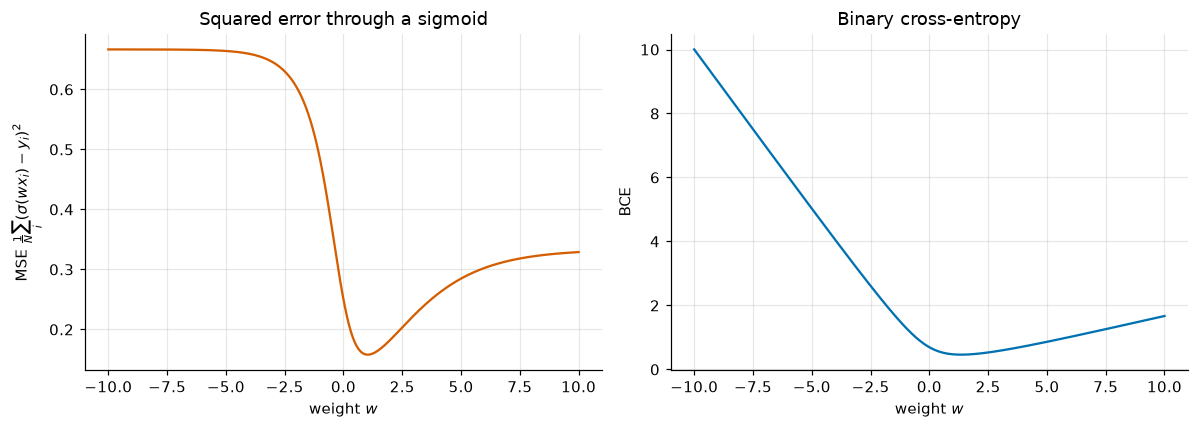

MSE: second difference negative (curving down) at 86% of grid points
BCE: second difference negative at 0% of grid points; smallest value 4.91e-08
MSE at w = -10 and w = +10: 0.6667, 0.3289


In [15]:
x_toy = torch.tensor([-2.0, -1.0, -0.5, 0.5, 1.0, 2.0], dtype=f64)   # (6,) one feature per example
y_toy = torch.tensor([0.0, 0.0, 1.0, 0.0, 1.0, 1.0], dtype=f64)      # (6,) two "overlapping" labels
w_grid = torch.linspace(-10, 10, 2001, dtype=f64)                     # (2001,) candidate weights
P_toy = torch.sigmoid(w_grid[:, None] * x_toy[None, :])               # (2001, 6)
mse_toy = ((P_toy - y_toy) ** 2).mean(dim=1)                          # (2001,)
bce_toy = -(y_toy * P_toy.log() + (1 - y_toy) * (1 - P_toy).log()).mean(dim=1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(w_grid, mse_toy, color=COLORS[1])
ax1.set_xlabel("weight $w$")
ax1.set_ylabel("MSE $\\frac{1}{N}\\sum_i(\\sigma(w x_i) - y_i)^2$")
ax1.set_title("Squared error through a sigmoid")
ax2.plot(w_grid, bce_toy, color=COLORS[0])
ax2.set_xlabel("weight $w$")
ax2.set_ylabel("BCE")
ax2.set_title("Binary cross-entropy")
plt.tight_layout()
plt.show()

d2_mse = mse_toy[2:] - 2 * mse_toy[1:-1] + mse_toy[:-2]   # second differences ≈ h² · L''(w)
d2_bce = bce_toy[2:] - 2 * bce_toy[1:-1] + bce_toy[:-2]
print(f"MSE: second difference negative (curving down) at {(d2_mse < 0).float().mean().item():.0%} of grid points")
print(f"BCE: second difference negative at {(d2_bce < 0).float().mean().item():.0%} of grid points; smallest value {d2_bce.min().item():.2e}")
print(f"MSE at w = -10 and w = +10: {mse_toy[0].item():.4f}, {mse_toy[-1].item():.4f}")

The MSE curve has a single valley but flattens into **plateaus** on both sides, and it bends downward (second derivative negative) over most of its length — it is not convex. For large $|w|$ every $\hat p_i$ is pinned at 0 or 1, the loss stops changing, and gradient descent started out there barely moves. The BCE curve keeps rising in both directions and curves upward everywhere: it is convex (Section 4 proves this in general). With more parameters, non-convex losses of this kind can also have separate local minima; for logistic regression we can avoid the question entirely.

**(b) Its gradient vanishes when the model is confidently wrong.** Take one example with $y = 1$ and logit $z$. By the chain rule, with $\sigma' = \hat p(1 - \hat p)$:

$$\frac{d}{dz}(\hat p - y)^2 = 2(\hat p - y)\,\hat p(1 - \hat p), \qquad \frac{d}{dz}\Big[-y\ln\hat p - (1-y)\ln(1-\hat p)\Big] = \hat p - y \quad (\text{derived below}).$$

When $z$ is very negative the model is confidently wrong: $\hat p \approx 0$, and the factor $\hat p(1 - \hat p)$ kills the squared-error gradient exactly when we need it most.

In [16]:
print(" logit z     p̂        MSE dℓ/dz     BCE dℓ/dz")
for zv in [-10.0, -5.0, 0.0, 2.0, 5.0]:
    z1 = torch.tensor(zv, dtype=f64, requires_grad=True)
    ((torch.sigmoid(z1) - 1.0) ** 2).backward()
    g_mse = z1.grad.item()
    z2 = torch.tensor(zv, dtype=f64, requires_grad=True)
    (-torch.log(torch.sigmoid(z2))).backward()
    g_bce = z2.grad.item()
    print(f"{zv:7.1f}  {torch.sigmoid(z1).item():.5f}   {g_mse:12.6f}   {g_bce:12.6f}")

 logit z     p̂        MSE dℓ/dz     BCE dℓ/dz
  -10.0  0.00005      -0.000091      -0.999955
   -5.0  0.00669      -0.013207      -0.993307
    0.0  0.50000      -0.250000      -0.500000
    2.0  0.88080      -0.025031      -0.119203
    5.0  0.99331      -0.000089      -0.006693


(Gradients from autograd, for the label $y = 1$.) At $z = -10$ the model gives the true class probability $4.5 \times 10^{-5}$ — very wrong — yet the squared-error gradient is about $10^{-4}$, ten thousand times weaker than BCE's $\approx -1$. Under BCE, the push is $\hat p - y$: as large as possible when the model is most wrong, and shrinking to 0 as it becomes right.

### The gradient of BCE

For one example, $\ell = -[y \ln \hat p + (1 - y)\ln(1 - \hat p)]$ with $\hat p = \sigma(z)$. Differentiate with respect to $\hat p$, then multiply by $d\hat p / dz = \hat p(1 - \hat p)$:

$$\frac{d\ell}{d\hat p} = -\frac{y}{\hat p} + \frac{1 - y}{1 - \hat p} = \frac{-y(1 - \hat p) + (1 - y)\hat p}{\hat p(1 - \hat p)} = \frac{\hat p - y}{\hat p(1 - \hat p)}, \qquad \frac{d\ell}{dz} = \frac{\hat p - y}{\hat p(1 - \hat p)}\cdot \hat p(1 - \hat p) = \hat p - y.$$

The sigmoid's derivative cancels completely. This is no accident: the logarithm in the likelihood undoes the exponential inside the sigmoid. The gradient with respect to the logit is just **prediction minus label**.

Now $z_i = \mathbf w \cdot \mathbf x_i + b$, so $\partial z_i / \partial \mathbf w = \mathbf x_i$ and $\partial z_i / \partial b = 1$. Averaging over examples, exactly as for the MSE in notebook 06 (Section 6):

$$\nabla_{\mathbf w} L = \frac1N\sum_{i=1}^N (\hat p_i - y_i)\,\mathbf x_i = \frac1N X^\top(\hat{\mathbf p} - \mathbf y) \quad \text{(shape } (D,)), \qquad \frac{\partial L}{\partial b} = \frac1N\sum_{i=1}^N(\hat p_i - y_i).$$

This is the linear-regression gradient with the residual $\hat y_i - y_i$ replaced by $\hat p_i - y_i$ (and no factor 2). We check it with autograd and with central finite differences (notebook 03), in `float64`, on the blob data at an arbitrary point:

In [17]:
def bce_loss(X, y, w, b):
    """Mean BCE of logistic regression, written directly from the definition.
    X: (N, D), y: (N,) in {0, 1}, w: (D,), b: () -> 0-d tensor. (Section 6 replaces this with a stable version.)"""
    p = torch.sigmoid(X @ w + b)                       # (N,)
    return -(y * torch.log(p) + (1 - y) * torch.log(1 - p)).mean()


def bce_grad(X, y, w, b):
    """Gradient of the mean BCE: returns (dL/dw of shape (D,), dL/db as a 0-d tensor)."""
    r = torch.sigmoid(X @ w + b) - y                   # (N,) "residuals" p̂ - y
    return X.T @ r / len(X), r.mean()


X64, y64 = X_blob.double(), y_blob.double()            # (N, 2), (N,)
w_at = torch.tensor([0.3, -0.8], dtype=f64, requires_grad=True)
b_at = torch.tensor(0.5, dtype=f64, requires_grad=True)
bce_loss(X64, y64, w_at, b_at).backward()
gw, gb = bce_grad(X64, y64, w_at.detach(), b_at.detach())

h = 1e-6
fd = []
for k in range(3):                                     # perturb w_1, w_2, b in turn
    e = torch.zeros(3, dtype=f64)
    e[k] = h
    theta = torch.cat([w_at.detach(), b_at.detach()[None]])
    L_plus = bce_loss(X64, y64, (theta + e)[:2], (theta + e)[2])
    L_minus = bce_loss(X64, y64, (theta - e)[:2], (theta - e)[2])
    fd.append(((L_plus - L_minus) / (2 * h)).item())
print("formula          :", [f"{v:.10f}" for v in [*gw.tolist(), gb.item()]])
print("autograd         :", [f"{v:.10f}" for v in [*w_at.grad.tolist(), b_at.grad.item()]])
print("finite difference:", [f"{v:.10f}" for v in fd])
check_close(gw, w_at.grad, "dL/dw vs autograd", rtol=1e-10, atol=1e-12)
check_close(gb, b_at.grad, "dL/db vs autograd", rtol=1e-10, atol=1e-12)
check_close(torch.cat([gw, gb[None]]), torch.tensor(fd, dtype=f64), "gradient vs finite differences", rtol=1e-7, atol=1e-9)
passed("BCE gradient formula matches autograd and finite differences")

formula          : ['-0.5403891956', '-0.7956117284', '0.0995380332']
autograd         : ['-0.5403891956', '-0.7956117284', '0.0995380332']
finite difference: ['-0.5403891956', '-0.7956117285', '0.0995380331']
✅ BCE gradient formula matches autograd and finite differences passed


Autograd agrees with the formula to all printed digits; the finite differences agree to about 9 digits, the accuracy limit of a `float64` central difference (notebook 03).

### Checkpoint 3.2

For the tiny dataset below (3 examples, 2 features), compute with the formula — no autograd — the probabilities `p_hat` (shape `(3,)`), the gradient `grad_w_small` (shape `(2,)`) and `grad_b_small` (0-d).

<details>
<summary><b>💡 Hint</b></summary>

`p_hat = torch.sigmoid(X_tiny @ w_tiny + b_tiny)`, then `r = p_hat - y_tiny`, `grad_w_small = X_tiny.T @ r / 3`, `grad_b_small = r.mean()`.

</details>

In [ ]:
X_tiny = torch.tensor([[1.0, 2.0], [-1.0, 0.5], [0.0, -1.0]])   # (3, 2)
y_tiny = torch.tensor([1.0, 0.0, 0.0])                          # (3,)
w_tiny, b_tiny = torch.tensor([0.5, -0.25]), torch.tensor(0.1)
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
check_shape(p_hat, (3,), "p_hat")
check_shape(grad_w_small, (2,), "grad_w_small")
_w = w_tiny.clone().requires_grad_(True)
_b = b_tiny.clone().requires_grad_(True)
bce_loss(X_tiny, y_tiny, _w, _b).backward()
check_close(p_hat, torch.sigmoid(X_tiny @ w_tiny + b_tiny), "p_hat")
check_close(grad_w_small, _w.grad, "grad_w_small")
check_close(grad_b_small, _b.grad, "grad_b_small")
passed("Checkpoint 3.2")

## 4. Convexity: one valley, no traps

Notebook 03 described a function's curvature by its **Hessian**, the matrix of second derivatives. Differentiate the gradient once more. Write $\mathbf a_i = (\mathbf x_i, 1)$ for example $i$ with a 1 appended, so that $z_i = \mathbf a_i \cdot \boldsymbol\theta$ with $\boldsymbol\theta = (\mathbf w, b)$, and stack the $\mathbf a_i$ as rows of the design matrix $A$ of shape `(N, D+1)` (notebook 06). The gradient is $\nabla L = \frac1N \sum_i (\hat p_i - y_i)\,\mathbf a_i$. Only $\hat p_i$ depends on $\boldsymbol\theta$, with $\nabla_{\boldsymbol\theta}\, \hat p_i = \hat p_i(1 - \hat p_i)\,\mathbf a_i$, so

$$H = \nabla^2 L = \frac1N\sum_{i=1}^N \hat p_i(1 - \hat p_i)\,\mathbf a_i \mathbf a_i^\top = \frac1N A^\top S A, \qquad S = \operatorname{diag}\big(\hat p_1(1-\hat p_1), \ldots, \hat p_N(1 - \hat p_N)\big).$$

The labels $y_i$ dropped out: the curvature depends only on the inputs and the current predictions.

**$H$ is positive semidefinite.** For any vector $\mathbf v$,

$$\mathbf v^\top H \mathbf v = \frac1N\sum_i \underbrace{\hat p_i(1 - \hat p_i)}_{> 0}\,(\mathbf a_i \cdot \mathbf v)^2 \ \ge\ 0,$$

so every eigenvalue of $H$ is $\ge 0$: the loss curves upward (or is flat) in every direction, at every $\boldsymbol\theta$. A function whose Hessian is positive semidefinite everywhere is **convex** (a standard calculus fact, stated without proof). We check the formula against autograd's Hessian (`torch.autograd.functional.hessian`) and look at its eigenvalues at a random point:

In [20]:
def bce_theta(theta, X, y):
    """BCE as a function of θ = (w, b) stacked into one vector of shape (D + 1,)."""
    return bce_loss(X, y, theta[:-1], theta[-1])


def bce_hessian(X, y, theta):
    """Hessian (1/N) Aᵀ S A of the mean BCE. X: (N, D), θ: (D + 1,) -> (D + 1, D + 1). (y is not needed.)"""
    A = torch.cat([X, torch.ones(len(X), 1, dtype=X.dtype)], dim=1)   # (N, D + 1)
    p = torch.sigmoid(A @ theta)                                      # (N,)
    return A.T @ (A * (p * (1 - p))[:, None]) / len(X)                # (D+1, D+1); scaling rows = A^T S A


set_seed(0)
theta_rand = torch.randn(3, dtype=f64)
H_formula = bce_hessian(X64, y64, theta_rand)
H_autograd = torch.autograd.functional.hessian(lambda t: bce_theta(t, X64, y64), theta_rand)
print("Hessian (formula):\n", H_formula)
print("max |formula - autograd| =", (H_formula - H_autograd).abs().max().item())
print("eigenvalues:", torch.linalg.eigvalsh(H_formula).tolist())
check_close(H_formula, H_autograd, "Hessian", rtol=1e-10, atol=1e-12)
passed("Hessian formula matches autograd")

Hessian (formula):
 tensor([[0.1865, 0.1123, 0.0978],
        [0.1123, 0.2365, 0.0484],
        [0.0978, 0.0484, 0.1069]], dtype=torch.float64)
max |formula - autograd| = 9.71445146547012e-17
eigenvalues: [0.03727949895289754, 0.1270267845345994, 0.3655810969490989]
✅ Hessian formula matches autograd passed


All three eigenvalues are positive. A picture of the same fact: slice the loss along random straight lines $\boldsymbol\theta_0 + t\,\mathbf v$ through parameter space. Every slice of a convex function is a convex 1-D function.

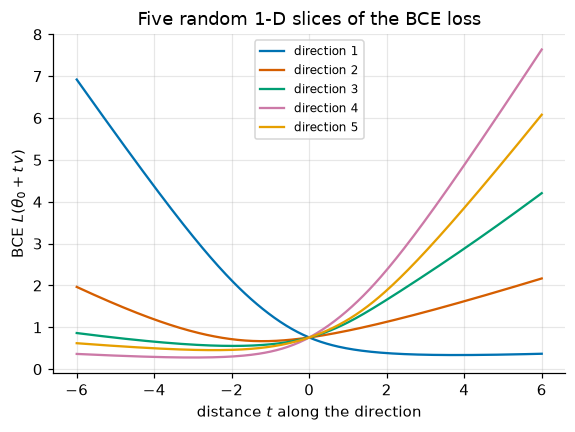

smallest second difference over all slices: 1.21e-05


In [21]:
set_seed(1)
ts = torch.linspace(-6, 6, 241, dtype=f64)
fig, ax = plt.subplots(figsize=(6, 4))
min_d2 = []
for k in range(5):
    v = torch.randn(3, dtype=f64)
    v = v / v.norm()                                                   # unit direction
    Ls = torch.stack([bce_theta(theta_rand + t * v, X64, y64) for t in ts])
    min_d2.append((Ls[2:] - 2 * Ls[1:-1] + Ls[:-2]).min().item())
    ax.plot(ts, Ls, color=COLORS[k], label=f"direction {k + 1}")
ax.set_xlabel("distance $t$ along the direction")
ax.set_ylabel("BCE $L(\\theta_0 + t\\,v)$")
ax.set_title("Five random 1-D slices of the BCE loss")
ax.legend(fontsize=8)
plt.show()
print("smallest second difference over all slices:", f"{min(min_d2):.2e}")

Each slice is a single bowl-shaped curve, and no second difference is negative: no plateaus that curve downward, no second valleys.

**Consequences** (standard results for convex functions, stated without proof):

- Every local minimum is a global minimum. If gradient descent (with a small enough $\eta$) settles anywhere, it has found the best possible $(\mathbf w, b)$.
- If the columns of $A$ are linearly independent (true for almost any real dataset with more examples than features), then $\mathbf v^\top H\mathbf v > 0$ for every $\mathbf v \ne \mathbf 0$, because every $\hat p_i(1 - \hat p_i)$ is strictly positive. The loss is then *strictly* convex and has **at most one** minimizer.

"At most one" is not "exactly one": Section 7 shows data for which no minimizer exists at all. And none of this survives into neural networks with hidden layers, whose losses are not convex; this is one of the last times we will have a guarantee like this.

### Checkpoint 4.1

Convexity does not depend on the data being easy. Using `bce_hessian`, compute the Hessian `H_xor` of the BCE on the XOR data below at the parameters `theta_xor`, and its smallest eigenvalue `eig_min_xor` (a float). Before running: what sign must it have?

<details>
<summary><b>💡 Hint</b></summary>

`torch.linalg.eigvalsh` returns the eigenvalues of a symmetric matrix in ascending order, so the smallest is element `[0]`.

</details>

In [ ]:
X_xor, y_xor = make_xor(n=400, seed=0)
X_xor64, y_xor64 = X_xor.double(), y_xor.double()
theta_xor = torch.tensor([2.0, -3.0, 0.5], dtype=f64)
# YOUR CODE HERE
raise NotImplementedError
print("smallest eigenvalue:", eig_min_xor)

In [ ]:
check_shape(H_xor, (3, 3), "H_xor")
check_close(H_xor, torch.autograd.functional.hessian(lambda t: bce_theta(t, X_xor64, y_xor64), theta_xor), "H_xor", rtol=1e-9, atol=1e-12)
check_close(eig_min_xor, torch.linalg.eigvalsh(H_xor)[0].item(), "eig_min_xor")
check(eig_min_xor >= 0, "the Hessian of the BCE is positive semidefinite, so its eigenvalues cannot be negative")
passed("Checkpoint 4.1")

## 5. Training logistic regression

Back to the overlapping blobs from the motivating problem: 200 points per class around $(-1, -1)$ and $(1, 1)$ with standard deviation 1.0.

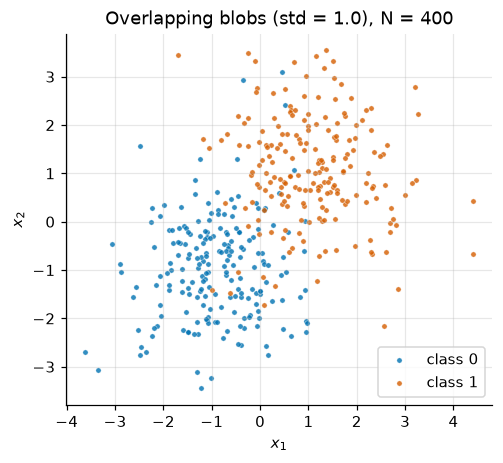

In [24]:
fig, ax = plt.subplots(figsize=(5, 5))
plot_dataset(X_blob, y_blob, ax=ax, title="Overlapping blobs (std = 1.0), N = 400")
ax.legend()
plt.show()

The clouds overlap in the middle, so no line can classify every point correctly.

### A reference answer

There is no closed form for the minimizer, unlike least squares. For a ground truth we use PyTorch's **L-BFGS** optimizer in `float64`. It builds an approximation of the curvature (the Hessian of Section 4) from recent gradients and converges in far fewer steps than plain gradient descent. We treat it as a tool here; the chapter problem set has you implement its exact relative, Newton's method. All we need is its output, and we can *verify* that output: if the gradient there is tiny, then by convexity (Section 4) the point is essentially the global minimum.

In [25]:
def reference_logistic(X, y):
    """Reference minimizer of the mean BCE by L-BFGS, in float64. Returns (w (D,), b ())."""
    X, y = X.double(), y.double()
    theta = torch.zeros(X.shape[1] + 1, dtype=f64, requires_grad=True)
    optimizer = torch.optim.LBFGS([theta], max_iter=500, tolerance_grad=1e-14, tolerance_change=1e-16,
                                  line_search_fn="strong_wolfe")

    def closure():
        optimizer.zero_grad()
        loss = F.binary_cross_entropy_with_logits(X @ theta[:-1] + theta[-1], y)
        loss.backward()
        return loss

    optimizer.step(closure)
    theta = theta.detach()
    return theta[:-1], theta[-1]


w_ref, b_ref = reference_logistic(X_blob, y_blob)
gw, gb = bce_grad(X64, y64, w_ref, b_ref)
print(f"reference: w = {w_ref.tolist()}, b = {b_ref.item():.10f}")
print(f"gradient norm at the reference: {torch.cat([gw, gb[None]]).norm().item():.1e}")
print(f"loss at the reference: {bce_loss(X64, y64, w_ref, b_ref).item():.8f}")

reference: w = [2.2414666727183485, 1.45576613966673], b = -0.1908987900
gradient norm at the reference: 1.0e-09
loss at the reference: 0.20206644


The gradient at the reference is about $10^{-9}$, millions of times smaller than at the start, so this is the global minimum to far more digits than we need.

### Gradient descent with manual gradients

Which learning rate? Every $\hat p_i(1 - \hat p_i) \le \frac14$, so $H \preceq \frac14 \cdot \frac1N A^\top A$: the curvature is never more than $\lambda_{\max}\!\big(\frac{1}{4N}A^\top A\big)$ in any direction. For such functions gradient descent decreases the loss for every $\eta$ below $2/\lambda_{\max}$ of that bound (stated without proof; it extends notebook 03's quadratic analysis).

In [26]:
A_blob = torch.cat([X64, torch.ones(N, 1, dtype=f64)], dim=1)                 # (N, 3)
lam_bound = torch.linalg.eigvalsh(A_blob.T @ A_blob / (4 * N))[-1].item()
print(f"curvature bound λmax(AᵀA/4N) = {lam_bound:.4f}  ->  safe learning rates η < {2 / lam_bound:.2f}")

ETA, STEPS = 1.0, 500
w, b = torch.zeros(2), torch.zeros(())          # float32, like real training
y_f = y_blob.float()                            # (N,) labels as floats in {0., 1.}
manual_losses = []
for step in range(STEPS):
    p = torch.sigmoid(X_blob @ w + b)           # (N,) forward pass
    manual_losses.append(-(y_f * torch.log(p) + (1 - y_f) * torch.log(1 - p)).mean().item())
    r = p - y_f                                 # (N,)
    w = w - ETA * X_blob.T @ r / N              # (D,)
    b = b - ETA * r.mean()
w_gd, b_gd = w, b
print(f"gradient descent: w = {w_gd.tolist()}, b = {b_gd.item():.6f}")
print(f"largest |GD - reference| = {(torch.cat([w_gd, b_gd[None]]).double() - torch.cat([w_ref, b_ref[None]])).abs().max().item():.1e}")
check_close(w_gd, w_ref.float(), "w after gradient descent", rtol=0, atol=1e-4)
check_close(b_gd, b_ref.float(), "b after gradient descent", rtol=0, atol=1e-4)
passed("Manual gradient descent reaches the reference minimum")

curvature bound λmax(AᵀA/4N) = 0.7665  ->  safe learning rates η < 2.61
gradient descent: w = [2.241462469100952, 1.455764651298523], b = -0.190899
largest |GD - reference| = 4.2e-06
✅ Manual gradient descent reaches the reference minimum passed


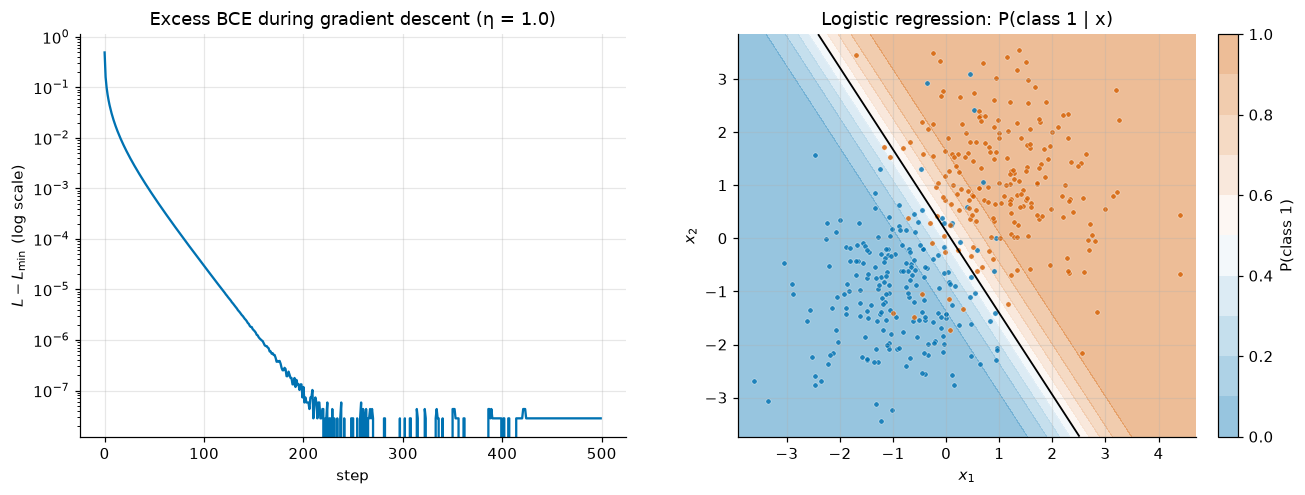

In [27]:
min_loss = bce_loss(X64, y64, w_ref, b_ref).item()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))
ax1.semilogy([l - min_loss for l in manual_losses], color=COLORS[0])
ax1.set_xlabel("step")
ax1.set_ylabel("$L - L_{\\min}$ (log scale)")
ax1.set_title(f"Excess BCE during gradient descent (η = {ETA})")
plot_decision_boundary(lambda G: torch.sigmoid(G @ w_gd + b_gd), X_blob, y_blob, ax=ax2, kind="prob",
                       title="Logistic regression: P(class 1 | x)")
plt.tight_layout()
plt.show()

Left: the excess loss falls steadily on a log scale — after a quick initial drop, roughly a straight line, the linear convergence notebook 03 found on quadratics — until around step 200 it hits the floor set by `float32` rounding (about $10^{-7}$) and just jitters there. It starts at $\ln 2 - L_{\min}$, because $\mathbf w = \mathbf 0, b = 0$ predicts $\hat p = \frac12$ for everything. Right: the black line is the boundary $\hat p = 0.5$, and the shading shows the probability changing smoothly across it. Points deep inside a cloud get probabilities near 0 or 1; points in the overlap get probabilities near $\frac12$ — the model says "I am not sure", which a perceptron cannot.

### The same with `nn.Linear`

In the standard PyTorch style (notebook 06), the model is `nn.Linear(2, 1)`, which outputs the **logit** $z$, shape `(N, 1)`; we squeeze it to `(N,)`. The loss is `nn.BCEWithLogitsLoss()`, which applies the sigmoid and the BCE together, taking **logits** — Section 6 explains why. Its targets must be floats of the same shape as the logits. Passing the `int64` labels from `make_blobs` directly is a common mistake:

In [28]:
try:
    F.binary_cross_entropy_with_logits(torch.zeros(N), y_blob)
except RuntimeError as err:
    print("RuntimeError:", err)

RuntimeError: result type Float can't be cast to the desired output type Long


In [29]:
set_seed(0)
model = nn.Linear(2, 1)                          # random initialization this time
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=ETA)
for step in range(STEPS):
    optimizer.zero_grad()
    logits = model(X_blob).squeeze(1)            # (N,)
    loss = loss_fn(logits, y_f)                  # targets: float, shape (N,)
    loss.backward()
    optimizer.step()

w_lin, b_lin = model.weight.detach().squeeze(0), model.bias.detach().squeeze(0)
print(f"nn.Linear: w = {w_lin.tolist()}, b = {b_lin.item():.6f}, final loss {loss.item():.6f}")
print(f"reference: w = {w_ref.float().tolist()}, b = {b_ref.item():.6f}, minimum   {min_loss:.6f}")
check_close(w_lin, w_ref.float(), "nn.Linear weight", rtol=0, atol=1e-4)
check_close(b_lin, b_ref.float(), "nn.Linear bias", rtol=0, atol=1e-4)
passed("nn.Linear + BCEWithLogitsLoss reaches the same minimum")

nn.Linear: w = [2.241462469100952, 1.4557645320892334], b = -0.190898, final loss 0.202066
reference: w = [2.241466760635376, 1.4557660818099976], b = -0.190899, minimum   0.202066
✅ nn.Linear + BCEWithLogitsLoss reaches the same minimum passed


From a random start instead of zero, the model reaches the same parameters: with a convex loss and a unique minimum, the starting point does not matter. (Compare the perceptron in the motivating problem, whose answer depended on when we stopped.)

### Checkpoint 5.1

Using the trained `model`, compute inside `torch.no_grad()` the predicted probabilities `probs` (shape `(N,)`) for `X_blob`, the predicted classes `preds` (shape `(N,)`, `int64`, 1 where the probability exceeds 0.5) and the training accuracy `acc` (a float).

<details>
<summary><b>💡 Hint</b></summary>

`model(X_blob)` gives logits of shape `(N, 1)`: squeeze, then `torch.sigmoid`. `(probs > 0.5).long()` gives the classes, and `(preds == y_blob).float().mean().item()` the accuracy.

</details>

In [ ]:
with torch.no_grad():
    # YOUR CODE HERE
    raise NotImplementedError
print(f"training accuracy: {acc:.4f}")

In [ ]:
check_shape(probs, (N,), "probs")
check_shape(preds, (N,), "preds")
check(preds.dtype == torch.int64, f"preds should be int64, got {preds.dtype}")
with torch.no_grad():
    _logits = model(X_blob).squeeze(1)
check_close(probs, torch.sigmoid(_logits), "probs")
check(torch.equal(preds, (_logits > 0).long()), "preds should be 1 exactly where the probability exceeds 0.5")
check_close(acc, ((_logits > 0).long() == y_blob).float().mean().item(), "acc")
passed("Checkpoint 5.1")

About 93% of training points are classified correctly. The remaining 7% lie in the overlap region, where any line must misclassify some points. Whether 93% is also what we would see on new points from the same distribution is the question of generalization (notebook 22).

## 6. Numerical stability: losses take logits

Our `bce_loss` computes $\sigma(z)$ and then its logarithm. Mathematically fine; numerically, in `float32`, it breaks for logits of moderate size:

In [32]:
z_big = torch.tensor([-100.0, -20.0, 0.0, 20.0, 100.0])     # float32 logits
p_big = torch.sigmoid(z_big)
print("σ(z)          :", p_big.tolist())
print("log σ(z)      :", torch.log(p_big).tolist())
print("log(1 - σ(z)) :", torch.log(1 - p_big).tolist())

σ(z)          : [0.0, 2.06115369216775e-09, 0.5, 1.0, 1.0]
log σ(z)      : [-inf, -20.0, -0.6931471824645996, 0.0, 0.0]
log(1 - σ(z)) : [0.0, 0.0, -0.6931471824645996, -inf, -inf]


$\sigma(-100) \approx 3.7 \times 10^{-44}$ comes out as exactly 0, and $\sigma(20) = 1 - 2 \times 10^{-9}$ rounds to exactly 1, since `float32` keeps only about 7 significant digits. The logs then return `-inf`, where the true values are about $-100$ and $-20$. So a confidently wrong prediction — $z = 20$ for a label 0 — produces an **infinite** loss. And the gradient is worse:

In [33]:
z_req = z_big.clone().requires_grad_(True)
y_zero = torch.zeros(5)
naive = -(y_zero * torch.log(torch.sigmoid(z_req)) + (1 - y_zero) * torch.log(1 - torch.sigmoid(z_req)))
naive.sum().backward()
print("naive BCE for label 0       :", naive.tolist())
print("its autograd gradient dℓ/dz :", z_req.grad.tolist())
print("true dℓ/dz = σ(z) - 0       :", torch.sigmoid(z_big).tolist())
print("F.binary_cross_entropy      :", F.binary_cross_entropy(torch.sigmoid(z_big), y_zero, reduction="none").tolist())

naive BCE for label 0       : [nan, -0.0, 0.6931471824645996, inf, inf]
its autograd gradient dℓ/dz : [nan, 2.06115369216775e-09, 0.5, nan, nan]
true dℓ/dz = σ(z) - 0       : [0.0, 2.06115369216775e-09, 0.5, 1.0, 1.0]
F.binary_cross_entropy      : [0.0, 2.06115369216775e-09, 0.6931471824645996, 100.0, 100.0]


Three of the five losses are wrong. At $z = 20$ and $100$ the loss is `inf`. At $z = -100$ — a *correct*, confident prediction — it is `nan`: the unused term $y \ln\hat p$ becomes $0 \cdot \ln 0 = 0 \cdot (-\infty)$, which is undefined in floating point (the $0 \log 0$ problem of notebook 04). The gradient is `nan` at all three (autograd multiplies an infinite derivative of $\log$ at 0 by a zero derivative of the saturated sigmoid). One such example in a batch makes every parameter `nan`. PyTorch's `F.binary_cross_entropy`, which takes *probabilities*, avoids `inf` by clamping each log at $-100$ (documented behaviour) — so it returns 100 for $z = 20$, where the true loss is 20. Finite, but wrong.

### The stable formula

Work with the logit and never form $\hat p$. Since $\sigma(z) = \frac{1}{1 + e^{-z}}$ and $1 - \sigma(z) = \sigma(-z)$:

$$-\ln\sigma(z) = \ln(1 + e^{-z}) = \operatorname{softplus}(-z), \qquad -\ln(1 - \sigma(z)) = \ln(1 + e^{z}) = \operatorname{softplus}(z).$$

Also $\operatorname{softplus}(-z) = \ln\big(e^{-z}(e^{z} + 1)\big) = \operatorname{softplus}(z) - z$. Substituting both into $\ell = y\,(-\ln\hat p) + (1-y)(-\ln(1-\hat p))$:

$$\ell(z, y) = y\big(\operatorname{softplus}(z) - z\big) + (1 - y)\operatorname{softplus}(z) = \operatorname{softplus}(z) - y\,z.$$

Notebook 05 (Section 8) computed softplus stably as $\operatorname{softplus}(z) = \max(z, 0) + \ln(1 + e^{-|z|})$, where $e^{-|z|} \le 1$ cannot overflow (the same idea as the stable log-sum-exp in the Chapter 1 problem set). So

$$\boxed{\ \ell(z, y) = \max(z, 0) - y\,z + \ln\!\big(1 + e^{-|z|}\big)\ }$$

and its derivative is $\sigma(z) - y$, as before. This is what `F.binary_cross_entropy_with_logits` and `nn.BCEWithLogitsLoss` compute.

In [34]:
def bce_with_logits_ref(z, y):
    """Per-example BCE from logits: max(z, 0) - y z + log(1 + e^{-|z|}). Same shape as z."""
    return z.clamp(min=0) - y * z + torch.log1p(torch.exp(-z.abs()))


for y_val in [0.0, 1.0]:
    y_vec = torch.full((5,), y_val)
    exact = F.softplus(z_big.double()) - y_val * z_big.double()       # float64: no rounding trouble for these z
    print(f"label {y_val:.0f}: stable formula  {bce_with_logits_ref(z_big, y_vec).tolist()}")
    print(f"         PyTorch (logits) {F.binary_cross_entropy_with_logits(z_big, y_vec, reduction='none').tolist()}")
    print(f"         float64 exact    {[float(f'{v:.6g}') for v in exact.tolist()]}")

z_req = z_big.clone().requires_grad_(True)
F.binary_cross_entropy_with_logits(z_req, y_zero, reduction="sum").backward()
print("gradient from F.binary_cross_entropy_with_logits, label 0:", z_req.grad.tolist())

label 0: stable formula  [3.923635700109488e-44, 2.06115369216775e-09, 0.6931471824645996, 20.0, 100.0]
         PyTorch (logits) [0.0, 0.0, 0.6931471824645996, 20.0, 100.0]
         float64 exact    [3.72008e-44, 2.06115e-09, 0.693147, 20.0, 100.0]
label 1: stable formula  [100.0, 20.0, 0.6931471824645996, 2.06115369216775e-09, 3.923635700109488e-44]
         PyTorch (logits) [100.0, 20.0, 0.6931471824645996, 2.06115369216775e-09, 3.923635700109488e-44]
         float64 exact    [100.0, 20.0, 0.693147, 2.06115e-09, 0.0]
gradient from F.binary_cross_entropy_with_logits, label 0: [0.0, 2.06115369216775e-09, 0.5, 1.0, 1.0]


The stable formula, PyTorch's logits version and the `float64` value agree: a confidently wrong logit of 20 costs 20 and one of 100 costs 100 — no `inf`, no `nan`, no clamping — and the gradient is exactly $\sigma(z) - y$, finite everywhere. The only differences are in losses below $10^{-8}$ (for example $2 \times 10^{-9}$ versus 0 at $z = -20$, label 0), where PyTorch's arrangement of the same formula rounds a tiny loss to 0 — an absolute error far too small to matter for training.

**Rule for the rest of the course: models output logits; losses take logits.** Do not put a sigmoid at the end of a model you train with BCE. Apply `torch.sigmoid` only when you need the probabilities themselves — to report or plot them. (Exercise 3 shows what happens if you break this rule.) The same rule, with softmax and `F.cross_entropy`, applies to $K > 2$ classes in notebook 10.

### Checkpoint 6.1

Write `stable_bce(z, y)` returning the per-example loss (same shape as `z`) for logits `z` and float labels `y`, using the boxed formula. Do not call `F.binary_cross_entropy_with_logits`, `F.softplus`, or `torch.sigmoid`.

<details>
<summary><b>💡 Hint</b></summary>

`z.clamp(min=0)` is $\max(z, 0)$; `torch.log1p(u)` computes $\ln(1 + u)$ accurately for small $u$; `z.abs()` is $|z|$.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
_z = torch.tensor([-1000.0, -100.0, -3.0, -1e-3, 0.0, 2.5, 100.0, 1000.0])
for _yv in [0.0, 1.0]:
    _y = torch.full_like(_z, _yv)
    _out = stable_bce(_z, _y)
    check_shape(_out, tuple(_z.shape), "stable_bce output")
    check(bool(torch.isfinite(_out).all()), f"stable_bce returned a non-finite value for label {_yv:.0f}: {_out.tolist()}")
    check_close(_out, F.binary_cross_entropy_with_logits(_z, _y, reduction="none"), f"stable_bce for label {_yv:.0f}", rtol=1e-6, atol=1e-6)
passed("Checkpoint 6.1")

## 7. Separable data: when there is no best answer

Section 4 promised *at most one* minimizer. Now the case with none. Blobs with a small standard deviation, 0.3, are linearly separable — a line classifies all 400 points correctly, as the run below confirms. Train on them with plain gradient descent for 20,000 steps and track $\|\mathbf w\|$ and the loss.

In [37]:
X_sep, y_sep = make_blobs(n=200, std=0.3, seed=0)             # (400, 2), (400,)
y_sep_f = y_sep.float()


def train_gd(X, y, lr, steps, l2=0.0, record_at=()):
    """Full-batch GD on mean BCE + l2 * ||w||², from zero. y: float (N,).
    Returns w, b, and a list of (step, ||w||, BCE, ||grad||) at the steps in record_at."""
    w, b = torch.zeros(X.shape[1]), torch.zeros(())
    history = []
    for step in range(1, steps + 1):
        r = torch.sigmoid(X @ w + b) - y                     # (N,)
        gw = X.T @ r / len(X) + 2 * l2 * w                   # gradient of the penalty λ||w||² is 2λw
        gb = r.mean()
        w, b = w - lr * gw, b - lr * gb
        if step in record_at:
            bce = F.binary_cross_entropy_with_logits(X @ w + b, y).item()
            history.append((step, w.norm().item(), bce, torch.cat([gw, gb[None]]).norm().item()))
    return w, b, history


record = sorted({int(v) for v in torch.logspace(0, math.log10(20_000), 60).tolist()} | {10, 100, 1000, 10_000})
w_sep, b_sep, hist_sep = train_gd(X_sep, y_sep_f, lr=1.0, steps=20_000, record_at=record)
w_l2, b_l2, hist_l2 = train_gd(X_sep, y_sep_f, lr=1.0, steps=20_000, l2=0.01, record_at=record)
acc_sep = (((X_sep @ w_sep + b_sep) > 0).long() == y_sep).float().mean().item()
print(f"training accuracy after 20,000 steps: {acc_sep:.4f}")
for step, wn, bce, gn in hist_sep:
    if step in (10, 100, 1000, 10_000, 20_000):
        print(f"step {step:6d}: ||w|| = {wn:6.3f}   BCE = {bce:.2e}   ||gradient|| = {gn:.1e}")

training accuracy after 20,000 steps: 1.0000
step     10: ||w|| =  2.131   BCE = 5.86e-02   ||gradient|| = 7.5e-02
step    100: ||w|| =  3.907   BCE = 8.90e-03   ||gradient|| = 8.4e-03
step   1000: ||w|| =  6.044   BCE = 1.56e-03   ||gradient|| = 1.1e-03
step  10000: ||w|| =  8.840   BCE = 2.55e-04   ||gradient|| = 1.5e-04
step  20000: ||w|| =  9.841   BCE = 1.42e-04   ||gradient|| = 7.8e-05


The accuracy is 100%, so the data are linearly separable. The loss keeps falling toward 0, roughly tenfold for every tenfold increase in steps, and $\|\mathbf w\|$ keeps growing — by about 2 to 3 for every tenfold increase. The gradient shrinks but never reaches 0.

**Why.** Suppose some $(\mathbf u, c)$ classifies every point correctly: $\mathbf u\cdot\mathbf x_i + c > 0$ exactly when $y_i = 1$. Scale it up by $k$. Every logit moves further to the correct side, so every $\ell_i$ falls, and as $k \to \infty$ the loss tends to 0. But $\hat p_i$ is never exactly 0 or 1, so the loss never *reaches* 0: the infimum is 0 and no finite $(\mathbf w, b)$ attains it. In fact the gradient is never zero: its component along $(\mathbf u, c)$ is $\frac1N\sum_i(\hat p_i - y_i)(\mathbf u\cdot\mathbf x_i + c)$, and every term is negative ($\hat p_i - y_i < 0$ exactly when $\mathbf u \cdot \mathbf x_i + c > 0$). So gradient descent always has a reason to keep moving, and the maximum-likelihood estimate **does not exist**.

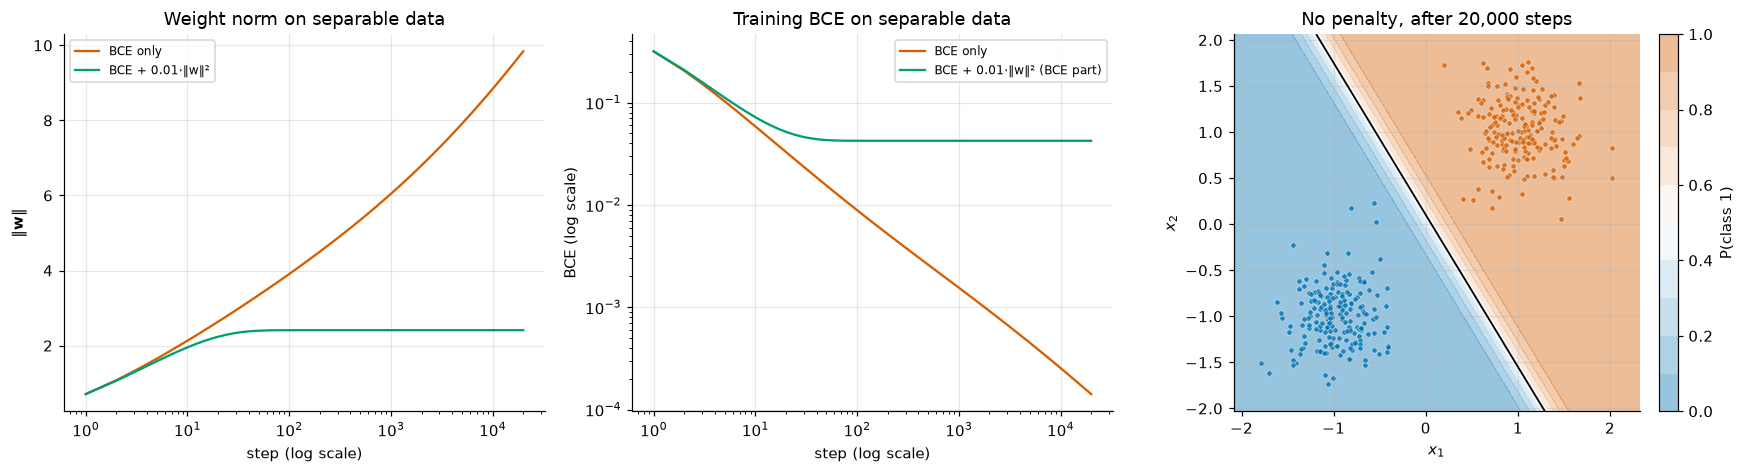

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
steps_rec = [h[0] for h in hist_sep]
axes[0].semilogx(steps_rec, [h[1] for h in hist_sep], color=COLORS[1], label="BCE only")
axes[0].semilogx(steps_rec, [h[1] for h in hist_l2], color=COLORS[2], label="BCE + 0.01·‖w‖²")
axes[0].set_xlabel("step (log scale)")
axes[0].set_ylabel("$\\|\\mathbf{w}\\|$")
axes[0].set_title("Weight norm on separable data")
axes[0].legend(fontsize=8)
axes[1].loglog(steps_rec, [h[2] for h in hist_sep], color=COLORS[1], label="BCE only")
axes[1].loglog(steps_rec, [h[2] for h in hist_l2], color=COLORS[2], label="BCE + 0.01·‖w‖² (BCE part)")
axes[1].set_xlabel("step (log scale)")
axes[1].set_ylabel("BCE (log scale)")
axes[1].set_title("Training BCE on separable data")
axes[1].legend(fontsize=8)
plot_decision_boundary(lambda G: torch.sigmoid(G @ w_sep + b_sep), X_sep, y_sep, ax=axes[2], kind="prob",
                       title="No penalty, after 20,000 steps")
plt.tight_layout()
plt.show()

Left: without a penalty, $\|\mathbf w\|$ keeps growing with no sign of levelling off (even on a logarithmic step axis). Middle: the loss falls along a straight line on log–log axes — like a power of the step count — and never levels off. Right: the band where $\hat p$ is between 0.1 and 0.9 has shrunk to a thin strip around the boundary. The sigmoid has become nearly a step, and the model claims near-certainty everywhere outside that strip — even in the empty gap between the clouds, where it has seen no data at all. That is overconfidence. (The *direction* of $\mathbf w$ does settle down; on separable data it is known to converge to the maximum-margin direction of the support vector machine — stated without proof.)

**The fix: a penalty.** Add $\lambda\|\mathbf w\|^2$ to the loss (here $\lambda = 0.01$; the bias is usually not penalized). Its gradient $2\lambda\mathbf w$ pulls the weights back, and its Hessian $2\lambda I$ adds to the BCE Hessian, making the $\mathbf w$-part strictly convex. Because the penalty grows without bound as $\|\mathbf w\| \to \infty$, the total loss now has a finite minimizer. The green curves show $\|\mathbf w\|$ levelling off:

In [39]:
step, wn, bce, gn = hist_l2[-1]
print(f"with L2 penalty, after {step} steps: ||w|| = {wn:.4f}, BCE part = {bce:.4f}, gradient norm = {gn:.1e}")
print(f"||w|| at step 1000 and 20000: {[h[1] for h in hist_l2 if h[0] >= 1000][0]:.6f}, {hist_l2[-1][1]:.6f}")

with L2 penalty, after 20000 steps: ||w|| = 2.4110, BCE part = 0.0424, gradient norm = 7.6e-08
||w|| at step 1000 and 20000: 2.410979, 2.410979


With the penalty, the gradient is zero to `float32` rounding: training has reached the (unique) minimizer, with a moderate $\|\mathbf w\|$ and probabilities that are not pushed to 0 and 1. The other common fix is **early stopping** — simply not running gradient descent for so long. Both are forms of regularization, the subject of Chapter 4.

## 8. Are the probabilities right?

We have been calling $\hat p$ a probability. A model is **calibrated** if, among all points where it says $\hat p \approx 0.7$, about 70% really are class 1. The simplest check is a **reliability diagram**: sort the predictions into bins by $\hat p$ and compare each bin's average prediction with the fraction of positives in it.

To see what "good" looks like, we generate data **from** a logistic model, so the model family is exactly right: $\mathbf x \sim \mathcal N(\mathbf 0, I)$ in 2-D, and $y \sim \text{Bernoulli}\big(\sigma(\mathbf w^* \cdot \mathbf x + b^*)\big)$ with $\mathbf w^* = (1.5, -1)$, $b^* = 0.5$. (This is not one of the course's shared datasets: the point is to know the true probabilities.)

In [40]:
gen = torch.Generator().manual_seed(0)
N_cal = 5000
W_TRUE, B_TRUE = torch.tensor([1.5, -1.0]), 0.5
X_cal = torch.randn(N_cal, 2, generator=gen)                       # (N_cal, 2)
p_true = torch.sigmoid(X_cal @ W_TRUE + B_TRUE)                     # (N_cal,) true P(y=1 | x)
y_cal = torch.bernoulli(p_true, generator=gen)                      # (N_cal,) float labels in {0., 1.}

w_cal, b_cal, _ = train_gd(X_cal, y_cal, lr=1.0, steps=500)
p_cal = torch.sigmoid(X_cal @ w_cal + b_cal)                        # (N_cal,) predicted probabilities
print(f"learned w = {[round(v, 3) for v in w_cal.tolist()]}, b = {b_cal.item():.3f}   (true: [1.5, -1.0], 0.5)")

n_bins = 10
bin_idx = (p_cal * n_bins).long().clamp(max=n_bins - 1)            # (N_cal,) bin 0 = [0, 0.1), ..., bin 9 = [0.9, 1]
counts = torch.bincount(bin_idx, minlength=n_bins)                  # (n_bins,)
mean_pred = torch.bincount(bin_idx, weights=p_cal, minlength=n_bins) / counts
frac_pos = torch.bincount(bin_idx, weights=y_cal, minlength=n_bins) / counts
print(" bin          count   mean p̂   fraction of 1s")
for k in range(n_bins):
    print(f" [{k / n_bins:.1f}, {(k + 1) / n_bins:.1f})   {counts[k].item():5d}    {mean_pred[k].item():.3f}     {frac_pos[k].item():.3f}")

learned w = [1.497, -1.008], b = 0.481   (true: [1.5, -1.0], 0.5)


 bin          count   mean p̂   fraction of 1s
 [0.0, 0.1)     348    0.056     0.055
 [0.1, 0.2)     398    0.150     0.126
 [0.2, 0.3)     408    0.251     0.279
 [0.3, 0.4)     439    0.352     0.330
 [0.4, 0.5)     445    0.451     0.465
 [0.5, 0.6)     424    0.549     0.568
 [0.6, 0.7)     524    0.652     0.660
 [0.7, 0.8)     516    0.752     0.746
 [0.8, 0.9)     651    0.852     0.849
 [0.9, 1.0)     847    0.950     0.943


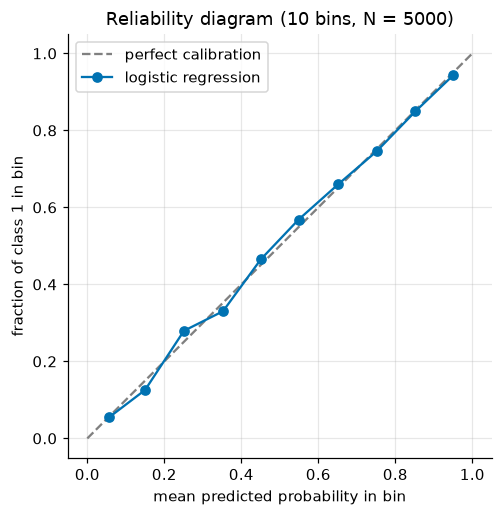

In [41]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], color="gray", ls="--", label="perfect calibration")
ax.plot(mean_pred, frac_pos, "o-", color=COLORS[0], label="logistic regression")
ax.set_xlabel("mean predicted probability in bin")
ax.set_ylabel("fraction of class 1 in bin")
ax.set_title("Reliability diagram (10 bins, N = 5000)")
ax.set_aspect("equal")
ax.legend()
plt.show()

The points lie close to the diagonal: when the data really come from a logistic model, the fitted probabilities are trustworthy. The small wiggles are sampling noise — each bin holds a few hundred labels, so the fraction of 1s itself is uncertain by a few percent.

Two caveats. We evaluated on the training data, which flatters any model; and real data are rarely generated by a logistic model, while deep networks are often noticeably *overconfident* (like the unpenalized model of Section 7). Notebook 25 studies calibration properly, on held-out data.

## Exercises

### Exercise 1 (modify): overlap, learning rate, and the size of $\mathbf w$

The cell below trains logistic regression with full-batch gradient descent (500 steps from zero, the `train_gd` of Section 7) on blobs with several standard deviations, prints $\|\mathbf w\|$, the final loss, and the accuracy, and shades $\hat p$ for each.

1. Run it with the given standard deviations. How do $\|\mathbf w\|$, the final loss, and the width of the "uncertain" band around the boundary change as the classes overlap more?
2. Change `stds` to `[0.3]` (the separable data of Section 7) and run again. What is different?
3. Set `stds = [1.0]` and try the learning rates `0.1` and `5.0`. Which results change, and which do not? Answer in the markdown cell below.

<details>
<summary><b>💡 Hint</b></summary>

The minimizer depends only on the data, not on $\eta$ — but with a small $\eta$, 500 steps may not reach it. Look at the gradient norm printed for each run: is training finished? For the separable case, recall Section 7.

</details>

std = 0.7: ||w|| = 4.911, final BCE = 0.0744, accuracy = 0.975, gradient norm = 1.2e-03
std = 1.0: ||w|| = 2.673, final BCE = 0.2021, accuracy = 0.933, gradient norm = 1.3e-07
std = 1.5: ||w|| = 1.287, final BCE = 0.3805, accuracy = 0.855, gradient norm = 5.7e-08


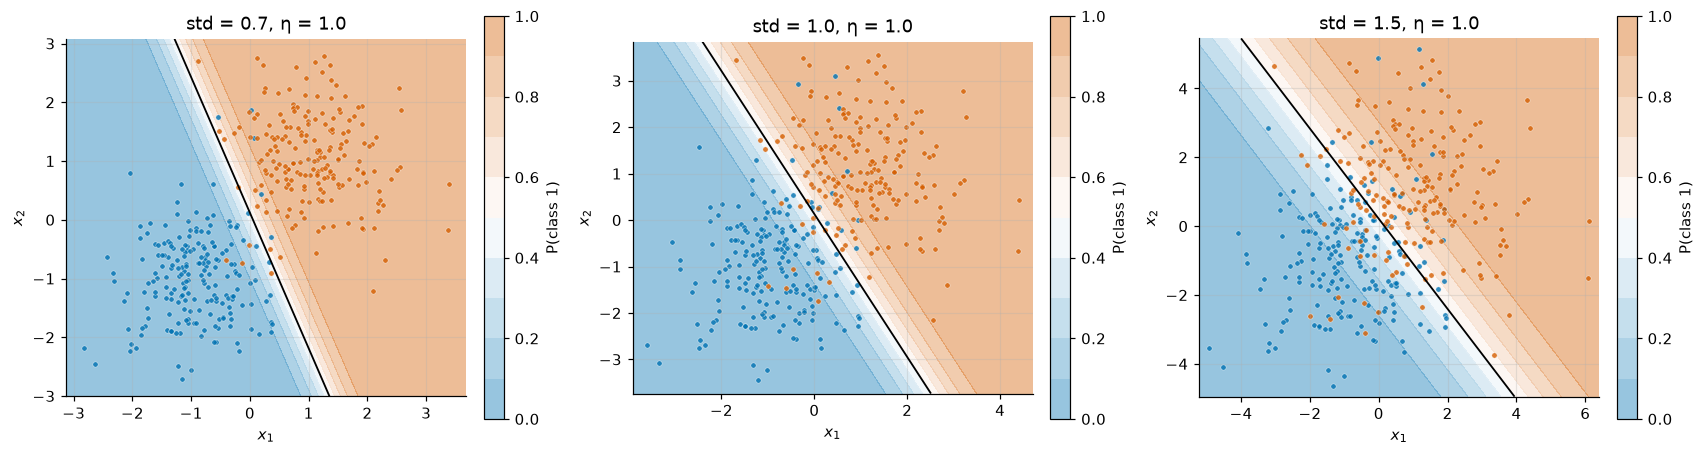

In [42]:
stds = [0.7, 1.0, 1.5]
lr_ex1, steps_ex1 = 1.0, 500

fig, axes = plt.subplots(1, len(stds), figsize=(5.2 * len(stds), 4.4), squeeze=False)
for ax, std in zip(axes[0], stds):
    X_e, y_e = make_blobs(n=200, std=std, seed=0)
    w_e, b_e, hist_e = train_gd(X_e, y_e.float(), lr=lr_ex1, steps=steps_ex1, record_at=(steps_ex1,))
    _, wn_e, bce_e, gn_e = hist_e[-1]
    acc_e = (((X_e @ w_e + b_e) > 0).long() == y_e).float().mean().item()
    print(f"std = {std}: ||w|| = {wn_e:.3f}, final BCE = {bce_e:.4f}, accuracy = {acc_e:.3f}, gradient norm = {gn_e:.1e}")
    plot_decision_boundary(lambda G: torch.sigmoid(G @ w_e + b_e), X_e, y_e, ax=ax, kind="prob",
                           title=f"std = {std}, η = {lr_ex1}")
plt.tight_layout()
plt.show()

*Your answer:*

### Exercise 2 (implement): logistic regression from scratch

Write `train_logistic_regression(X, y, lr, steps)` for `X` of shape `(N, D)` and labels `y` of shape `(N,)` with values in $\{0, 1\}$ (any dtype). Start from $\mathbf w = \mathbf 0$ (shape `(D,)`) and $b = 0$ in the dtype of `X`, run `steps` full-batch gradient-descent steps on the mean BCE using the gradient of Section 3 — **no autograd, no `nn.Module`** — and return `(w, b)` with `b` a 0-d tensor.

The check runs it in `float64` and compares with the L-BFGS reference, and confirms the gradient at your answer is essentially zero.

<details>
<summary><b>💡 Hint</b></summary>

Convert the labels once: `y = y.to(X.dtype)`. Then in the loop: `r = torch.sigmoid(X @ w + b) - y` (shape `(N,)`), `w = w - lr * X.T @ r / N`, `b = b - lr * r.mean()`. The gradient never needs the loss itself.

</details>

In [ ]:
def train_logistic_regression(X, y, lr, steps):
    # YOUR CODE HERE
    raise NotImplementedError

In [ ]:
w_ex2, b_ex2 = train_logistic_regression(X64, y_blob, lr=1.0, steps=2000)
check_shape(w_ex2, (2,), "w")
check_shape(b_ex2, (), "b")
check(not w_ex2.requires_grad, "do not use autograd: w should not require gradients")
check(w_ex2.dtype == f64, f"w should have the dtype of X (float64), got {w_ex2.dtype}")
check_close(w_ex2, w_ref, "w", rtol=0, atol=1e-6)
check_close(b_ex2, b_ref, "b", rtol=0, atol=1e-6)
_gw, _gb = bce_grad(X64, y64, w_ex2, b_ex2)
check(torch.cat([_gw, _gb[None]]).norm().item() < 1e-8, "the gradient at your solution should be essentially zero")
# A second dataset with D = 3 features
_X3, _y3 = make_blobs(n=150, centers=((0.0, 0.0, 0.0), (1.0, 1.0, 1.0)), std=1.0, seed=4)
_w3, _b3 = train_logistic_regression(_X3.double(), _y3, lr=1.0, steps=2000)
_w3_ref, _b3_ref = reference_logistic(_X3, _y3)
check_shape(_w3, (3,), "w for D = 3")
check_close(_w3, _w3_ref, "w for D = 3", rtol=0, atol=1e-6)
check_close(_b3, _b3_ref, "b for D = 3", rtol=0, atol=1e-6)
passed("Exercise 2")

### Exercise 3 (debug): probabilities stuck between 0.5 and 0.73

This function trains a classifier and returns its predicted probabilities for `X`. The buggy version (in the comments) runs without any error and its loss decreases — but every returned probability lies between 0.5 and 0.73, so every point is classified as class 1, and the loss refuses to fall below about 0.5. Find the bug and write the corrected function body.

<details>
<summary><b>💡 Hint</b></summary>

What does `model(X)` return in the buggy version — logits or probabilities? What does `binary_cross_entropy_with_logits` expect? Apply both to a logit of $\pm\infty$ and see what range of numbers comes out.

</details>

In [ ]:
def fit_and_predict_proba(X, y, lr=1.0, steps=500):
    """Train logistic regression on X (N, 2), y (N,) in {0, 1}; return P(y = 1 | x) for each row, shape (N,)."""
    set_seed(0)
    # Buggy version:
    #     model = nn.Sequential(nn.Linear(2, 1), nn.Sigmoid())
    #     optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    #     for _ in range(steps):
    #         optimizer.zero_grad()
    #         loss = F.binary_cross_entropy_with_logits(model(X).squeeze(1), y.float())
    #         loss.backward()
    #         optimizer.step()
    #     with torch.no_grad():
    #         return torch.sigmoid(model(X).squeeze(1))
    # YOUR CODE HERE
    raise NotImplementedError

In [ ]:
_p = fit_and_predict_proba(X_blob, y_blob)
check_shape(_p, (N,), "returned probabilities")
check(_p.min().item() < 0.1 and _p.max().item() > 0.9,
      f"probabilities range from {_p.min().item():.3f} to {_p.max().item():.3f}; a trained model on this data should reach below 0.1 and above 0.9")
_acc = ((_p > 0.5).long() == y_blob).float().mean().item()
check(_acc > 0.9, f"accuracy {_acc:.3f}: expected about 0.93")
check_close(F.binary_cross_entropy(_p.double(), y64).item(), min_loss, "BCE of the returned probabilities", rtol=0, atol=1e-3)
passed("Exercise 3")

To see what the bug does, here is the buggy version run directly, with the loss floor it cannot get below:

In [47]:
set_seed(0)
buggy = nn.Sequential(nn.Linear(2, 1), nn.Sigmoid())
opt_b = torch.optim.SGD(buggy.parameters(), lr=1.0)
for _ in range(500):
    opt_b.zero_grad()
    loss_b = F.binary_cross_entropy_with_logits(buggy(X_blob).squeeze(1), y_f)
    loss_b.backward()
    opt_b.step()
with torch.no_grad():
    p_b = torch.sigmoid(buggy(X_blob).squeeze(1))
    inner_acc = (((buggy[0](X_blob).squeeze(1)) > 0).long() == y_blob).float().mean().item()
floor = 0.5 * math.log(2) + 0.5 * -math.log(torch.sigmoid(torch.tensor(1.0)).item())
print(f"buggy: final loss {loss_b.item():.4f} (floor for balanced classes: {floor:.4f}; correct minimum {min_loss:.4f})")
print(f"buggy: 'probabilities' range from {p_b.min().item():.4f} to {p_b.max().item():.4f}; accuracy at threshold 0.5: "
      f"{((p_b > 0.5).long() == y_blob).float().mean().item():.4f}")
print(f"buggy: accuracy of the inner linear layer's sign: {inner_acc:.4f}")
print("BCE with labels in {-1, +1} instead of {0, 1}, logits -5, 0, 5:",
      F.binary_cross_entropy_with_logits(torch.tensor([-5.0, 0.0, 5.0]), -torch.ones(3), reduction="none").tolist())

buggy: final loss 0.5395 (floor for balanced classes: 0.5032; correct minimum 0.2021)
buggy: 'probabilities' range from 0.5000 to 0.7311; accuracy at threshold 0.5: 0.5125
buggy: accuracy of the inner linear layer's sign: 0.9300
BCE with labels in {-1, +1} instead of {0, 1}, logits -5, 0, 5: [-4.993284702301025, 0.6931471824645996, 10.006715774536133]


### Exercise 4 (investigate): perceptron versus logistic regression

The motivating problem suggested that on overlapping classes, the perceptron's answer depends on details that should not matter. The scaffold trains, on the overlapping blobs (std = 1.0):

- the **perceptron** for 20 epochs, with 10 different seeds for the order in which examples are visited;
- **logistic regression** by gradient descent (500 steps, $\eta = 1$) from 10 different random initializations,

and records the direction of each learned $\mathbf w$ (the angle $\operatorname{atan2}(w_2, w_1)$ in degrees) and the training accuracy, then draws all boundaries. Run it and answer in the markdown cell:

1. How much do the perceptron's boundaries vary from run to run? And logistic regression's?
2. Which method gets the higher training accuracy, and how consistently?
3. Explain both observations using what this notebook established about the logistic loss. Optionally, change `epochs` (e.g. 21, 50) and see whether the perceptron's runs agree more.

<details>
<summary><b>💡 Hint</b></summary>

The perceptron changes $\mathbf w$ after every mistake, and on non-separable data there is a mistake in every epoch (notebook 08). Gradient descent on a strictly convex loss with a minimizer converges to that one minimizer from any start (Sections 4–5).

</details>

perceptron           angle of w:    5.8° to   50.0°   accuracy: 0.863 to 0.930
logistic regression  angle of w:   33.0° to   33.0°   accuracy: 0.933 to 0.933


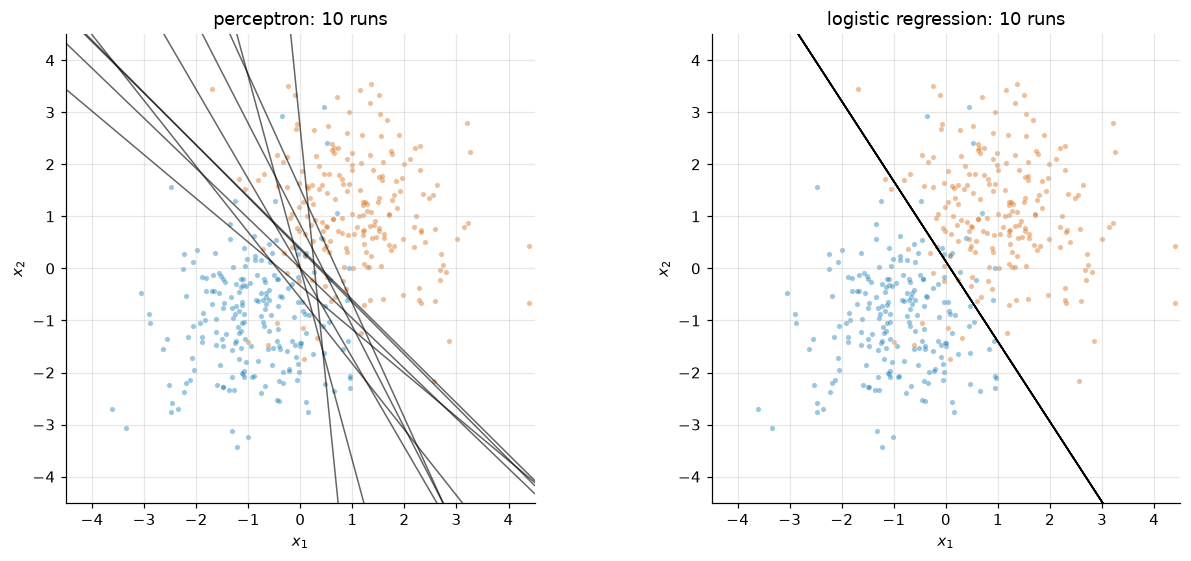

In [48]:
def logreg_from_random_init(X, y, seed, lr=1.0, steps=500):
    """Full-batch GD on mean BCE from a seeded random (w, b)."""
    gen = torch.Generator().manual_seed(seed)
    w, b = torch.randn(X.shape[1], generator=gen), torch.randn((), generator=gen)
    y = y.float()
    for _ in range(steps):
        r = torch.sigmoid(X @ w + b) - y
        w, b = w - lr * X.T @ r / len(X), b - lr * r.mean()
    return w, b


epochs, seeds = 20, range(10)
results = {"perceptron": [], "logistic regression": []}
for seed in seeds:
    w_p, b_p, _ = perceptron_train(X_blob, y_blob, epochs, seed)
    results["perceptron"].append((w_p, b_p))
    results["logistic regression"].append(logreg_from_random_init(X_blob, y_blob, seed))

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
x1_line = torch.linspace(-4.5, 4.5, 2)
for ax, (name, runs) in zip(axes, results.items()):
    plot_dataset(X_blob, y_blob, ax=ax, alpha=0.4)
    angles, accs = [], []
    for k, (w_k, b_k) in enumerate(runs):
        angles.append(math.degrees(math.atan2(w_k[1].item(), w_k[0].item())))
        accs.append((((X_blob @ w_k + b_k) > 0).long() == y_blob).float().mean().item())
        ax.plot(x1_line, -(w_k[0] * x1_line + b_k) / w_k[1], color="k", lw=1, alpha=0.6)   # w1 x1 + w2 x2 + b = 0
    ax.set_xlim(-4.5, 4.5)
    ax.set_ylim(-4.5, 4.5)
    ax.set_title(f"{name}: {len(runs)} runs")
    print(f"{name:20s} angle of w: {min(angles):6.1f}° to {max(angles):6.1f}°   "
          f"accuracy: {min(accs):.3f} to {max(accs):.3f}")
plt.tight_layout()
plt.show()

*Your conclusion:*

## Summary and what's next

- Logistic regression replaces the perceptron's step by the sigmoid: $\hat p = \sigma(\mathbf w\cdot\mathbf x + b) = P(y = 1 \mid \mathbf x)$. The decision boundary is still the line $\mathbf w\cdot\mathbf x + b = 0$, but now $\|\mathbf w\|$ sets how sharply the probability changes across it.
- The model is linear in the **log-odds**: $\operatorname{logit}(\hat p) = \mathbf w\cdot\mathbf x + b$, and increasing $x_j$ by 1 multiplies the odds by $e^{w_j}$.
- The loss is the Bernoulli negative log-likelihood, **binary cross-entropy**. Squared error on probabilities is non-convex and its gradient vanishes for confidently wrong predictions. BCE's gradient is clean: $\partial\ell/\partial z = \hat p - y$, so $\nabla_{\mathbf w}L = \frac1N X^\top(\hat{\mathbf p} - \mathbf y)$.
- The Hessian $\frac1N A^\top S A$ is positive semidefinite, so the loss is **convex**: gradient descent finds the global minimum when one exists, from any start. We verified this against autograd and finite differences, and gradient descent reached the same minimum as an independent L-BFGS reference.
- **Models output logits; losses take logits.** $\ell = \max(z, 0) - yz + \ln(1 + e^{-|z|})$ is stable for any $z$; `F.binary_cross_entropy_with_logits` / `nn.BCEWithLogitsLoss` compute it. Probabilities first, logs second gives `inf` and `nan`.
- On linearly **separable** data the minimizer does not exist: $\|\mathbf w\|$ grows forever and the model becomes overconfident. An L2 penalty (or early stopping) restores a finite answer — a first glimpse of regularization (Chapter 4).
- When the data really follow a logistic model, the predicted probabilities are well calibrated (notebook 25 goes further).

Still unsolved: the model handles exactly **two** classes. Recognizing digits, words, or objects means choosing among $K > 2$ classes. Notebook 10 generalizes the sigmoid to the **softmax** and binary cross-entropy to categorical cross-entropy — with the same "logits in, stable loss out" rule. And the boundary is still a single straight line, so XOR (notebook 08) remains out of reach until notebook 11 combines several of these units into a network.